In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sn = pd.read_csv("../_supernova/results/sn_profile.csv")
bao = pd.read_csv("../_bao/results/bao_profile.csv")

sn_summary = pd.read_csv("../_supernova/results/sn_summary.csv")
bao_summary = pd.read_csv("../_bao/results/bao_summary.csv")

assert len(sn) == len(bao)
assert np.allclose(sn["Omega_m"], bao["Omega_m"])

In [2]:
omega_m = sn["Omega_m"].values
chi2 = sn["chi2"].values + bao["chi2"].values

best = np.argmin(chi2)
dchi2 = chi2 - chi2[best]

assert 0 < best < len(omega_m) - 1
assert dchi2[0] > 1 and dchi2[-1] > 1

lower = np.interp(
    1, dchi2[:best + 1][::-1], omega_m[:best + 1][::-1]
)
upper = np.interp(
    1, dchi2[best:], omega_m[best:]
)

dof = int(sn_summary.loc[0, "dof"] + bao_summary.loc[0, "dof"] + 1)

joint_summary = pd.DataFrame({
    "Omega_m": [omega_m[best]],
    "error_minus": [omega_m[best] - lower],
    "error_plus": [upper - omega_m[best]],
    "lower_68": [lower],
    "upper_68": [upper],
    "offset": [sn.loc[best, "offset"]],
    "A": [bao.loc[best, "A"]],
    "chi2": [chi2[best]],
    "dof": [dof],
    "reduced_chi2": [chi2[best] / dof],
})

joint_summary.to_csv("results/joint_summary.csv", index=False)

pd.DataFrame({
    "Omega_m": omega_m,
    "chi2": chi2,
    "delta_chi2": dchi2,
}).to_csv("results/joint_profile.csv", index=False)

joint_summary

,Omega_m,error_minus,error_plus,lower_68,upper_68,offset,A,chi2,dof,reduced_chi2
0,0.304,0.007609,0.008247,0.296391,0.312247,23.798292,29.673749,1416.140509,1600,0.885088


In [3]:
comparison = pd.concat(
    [sn_summary, bao_summary, joint_summary],
    ignore_index=True,
)

comparison["data"] = ["SN", "BAO", "SN + BAO"]
comparison = comparison[
    ["data", "Omega_m", "error_minus", "error_plus", "lower_68", "upper_68"]
]

comparison.to_csv("results/omega_m_comparison.csv", index=False)

comparison

,data,Omega_m,error_minus,error_plus,lower_68,upper_68
0,SN,0.332,0.018389,0.018004,0.313611,0.350004
1,BAO,0.297,0.008026,0.009223,0.288974,0.306223
2,SN + BAO,0.304,0.007609,0.008247,0.296391,0.312247


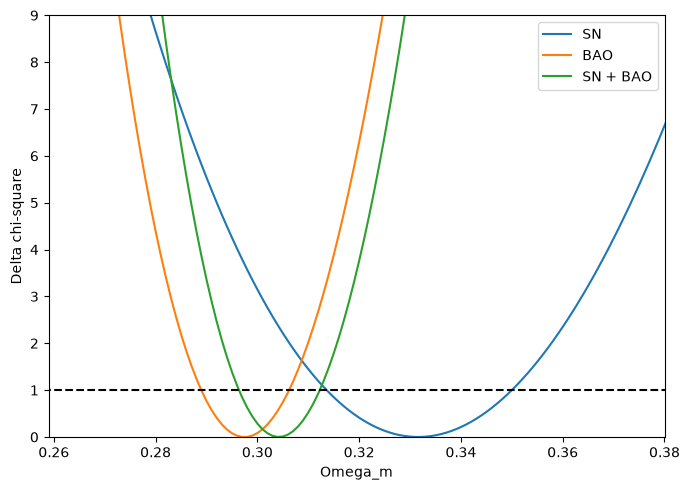

In [4]:
plt.figure(figsize=(7, 5))

plt.plot(omega_m, sn["delta_chi2"], label="SN")
plt.plot(omega_m, bao["delta_chi2"], label="BAO")
plt.plot(omega_m, dchi2, label="SN + BAO")
plt.plot([omega_m[0], omega_m[-1]], [1, 1], "k--")

plt.axis([
    min(comparison["lower_68"]) - 0.03,
    max(comparison["upper_68"]) + 0.03,
    0, 9,
])

plt.xlabel("Omega_m")
plt.ylabel("Delta chi-square")
plt.legend()
plt.tight_layout()
plt.show()